# Q13: Time Series Data Analysis

**Problem Statement:** Analysis and Visualization of Stock Market Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

stocks = pd.read_csv("Stock_Prices.csv", parse_dates=["Date"]).sort_values("Date").set_index("Date")
print("Rows and columns:", stocks.shape)
print(stocks.head().to_string())
print("Date span:", stocks.index.min().date(), "to", stocks.index.max().date())


Rows and columns: (260, 3)
             Close  Volume  MarketIndex
Date                                   
2024-01-01  102.97  325195     17998.28
2024-01-02  105.27  309874     18004.02
2024-01-03  105.72  106315     17993.29
2024-01-04  106.59  208729     18085.50
2024-01-05  106.40  333653     18070.59
Date span: 2024-01-01 to 2024-12-27


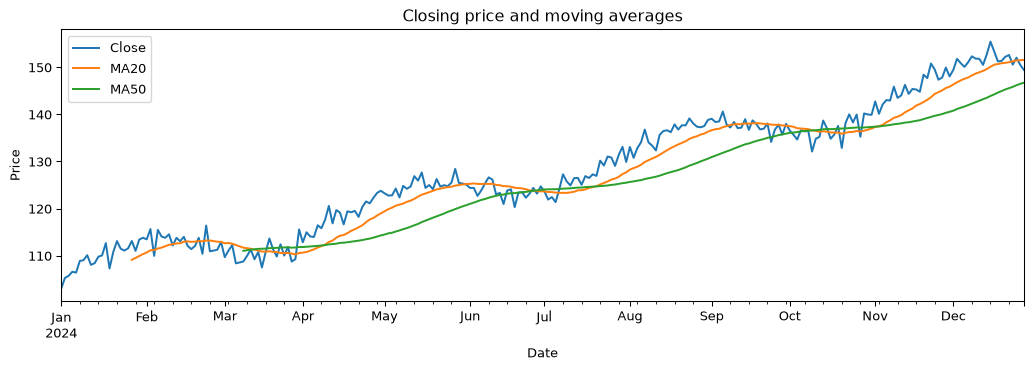

In [2]:
# Plot historical prices and 20/50-day rolling averages.
stocks["MA20"] = stocks["Close"].rolling(20).mean()
stocks["MA50"] = stocks["Close"].rolling(50).mean()
stocks[["Close", "MA20", "MA50"]].plot(figsize=(11, 4), title="Closing price and moving averages")
plt.ylabel("Price")
plt.tight_layout()
plt.show()


Mean daily return by weekday:
 Date
Monday      -0.042
Tuesday      0.528
Wednesday   -0.119
Thursday    -0.171
Friday       0.588 %
Close/volume/market correlations:
              Close  Volume  MarketIndex
Close        1.000  -0.060        0.915
Volume      -0.060   1.000       -0.061
MarketIndex  0.915  -0.061        1.000


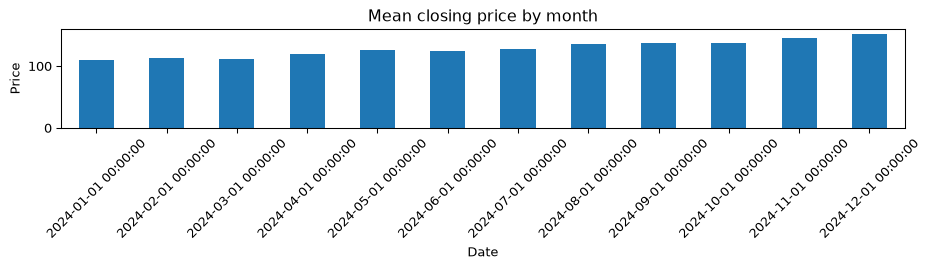

In [3]:
# Inspect possible weekday/monthly patterns and correlation with the market.
weekday_change = stocks["Close"].pct_change().groupby(stocks.index.day_name()).mean().reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"])
monthly_close = stocks["Close"].resample("MS").mean()
print("Mean daily return by weekday:\n", (weekday_change * 100).round(3).to_string(), "%")
print("Close/volume/market correlations:\n", stocks[["Close", "Volume", "MarketIndex"]].corr().round(3).to_string())
monthly_close.plot.bar(figsize=(10, 3), title="Mean closing price by month")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [4]:
# Holt's linear exponential smoothing: fit only on the training period.
train = stocks["Close"].iloc[:-30]
test = stocks["Close"].iloc[-30:]
alpha, beta = 0.35, 0.08
level = float(train.iloc[0])
trend = float(train.iloc[1] - train.iloc[0])
for value in train.iloc[1:]:
    old_level = level
    level = alpha * float(value) + (1 - alpha) * (level + trend)
    trend = beta * (level - old_level) + (1 - beta) * trend
forecast = pd.Series(level + np.arange(1, len(test) + 1) * trend, index=test.index, name="Forecast")
mae = (forecast - test).abs().mean()
print("Held-out mean absolute error:", round(mae, 2))
print(pd.DataFrame({"Actual": test, "Forecast": forecast}).head().round(2).to_string())


Held-out mean absolute error: 1.98
            Actual  Forecast
Date                        
2024-11-18  145.27    145.91
2024-11-19  144.78    146.29
2024-11-20  148.41    146.67
2024-11-21  147.69    147.06
2024-11-22  150.78    147.44


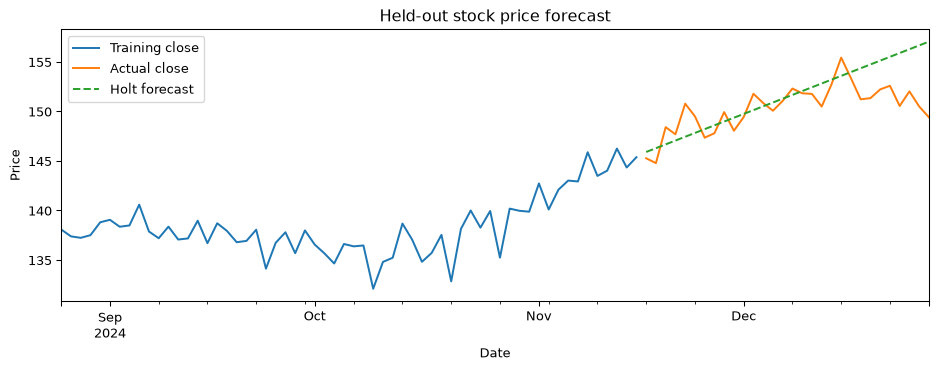

In [5]:
# Compare the held-out prices with the exponential-smoothing forecast.
ax = train.iloc[-60:].plot(figsize=(10, 4), label="Training close")
test.plot(ax=ax, label="Actual close")
forecast.plot(ax=ax, label="Holt forecast", linestyle="--")
ax.set(title="Held-out stock price forecast", ylabel="Price")
ax.legend()
plt.tight_layout()
plt.show()
